In [1]:
import pandas as pd
import matplotlib.pyplot as plt

lmp = pd.read_parquet("../data/processed/lmp_2025.parquet")

In [2]:
# Isolating the BGE and Western Hub day ahead data
bge_da_iso = lmp[(lmp["market"] == "DA") & (lmp["node"] == "BGE")]
wh_da_iso = lmp[(lmp["market"] == "DA") & (lmp["node"] == "WESTERN HUB")]

In [3]:
# Targeting the BGE LMP, Congestion, and Loss columns
bge_da_iso = bge_da_iso[["lmp","congestion","loss"]]

In [4]:
# Targeting the WH LMP, Congestion, and Loss columns
wh_da_iso = wh_da_iso[["lmp","congestion","loss"]]

In [5]:
bge_da_iso.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8760 entries, 2025-01-01 05:00:00+00:00 to 2026-01-01 04:00:00+00:00
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lmp         8760 non-null   float64
 1   congestion  8760 non-null   float64
 2   loss        8760 non-null   float64
dtypes: float64(3)
memory usage: 273.8 KB


In [6]:
wh_da_iso.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8760 entries, 2025-01-01 05:00:00+00:00 to 2026-01-01 04:00:00+00:00
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lmp         8760 non-null   float64
 1   congestion  8760 non-null   float64
 2   loss        8760 non-null   float64
dtypes: float64(3)
memory usage: 273.8 KB


In [7]:
# Creating a new table that contains the hourly difference between BGE and WH prices
price_diff = (bge_da_iso - wh_da_iso)

In [8]:
price_diff.describe()

,lmp,congestion,loss
count,8760.000000,8760.000000,8760.000000
mean,7.126420,5.721294,1.405126
std,15.314733,14.194111,1.731991
min,-78.183835,-79.612198,-0.601255
25%,0.804308,0.000000,0.538582
50%,3.247057,2.282188,0.960789
75%,9.647221,8.130707,1.652793
max,288.912323,268.712153,30.967041


In [9]:
# Creating an assert to ensure that Congestion + Loss is always equal to the difference in prices between BGE and WH
gap = (price_diff["lmp"]) - ((price_diff["congestion"] + price_diff["loss"]))
assert gap.abs().max() <= 0.01, "Congestion difference and Loss difference does not equal LMP difference (error is greater than $0.01)"

In [10]:
# Converting the index to Eastern time
price_diff.index = price_diff.index.tz_convert("America/New_York")

In [11]:
# Creating a table that highlights the average price difference in each month
monthly_price_diff = price_diff.resample("MS").mean()

In [12]:
monthly_price_diff.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 12 entries, 2025-01-01 00:00:00-05:00 to 2025-12-01 00:00:00-05:00
Freq: MS
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lmp         12 non-null     float64
 1   congestion  12 non-null     float64
 2   loss        12 non-null     float64
dtypes: float64(3)
memory usage: 384.0 bytes


In [13]:
monthly_price_diff.head()

,lmp,congestion,loss
2025-01-01 00:00:00-05:00,8.585105,6.381297,2.203808
2025-02-01 00:00:00-05:00,1.302011,0.089720,1.212291
2025-03-01 00:00:00-05:00,5.953184,5.294125,0.659059
2025-04-01 00:00:00-04:00,6.616889,5.744317,0.872572
2025-05-01 00:00:00-04:00,5.416634,4.146613,1.270021


In [14]:
# Calculating the mean annual price difference 
price_diff.mean()

lmp           7.126420
congestion    5.721294
loss          1.405126
dtype: float64

In [15]:
# Calculating what percentage of the price difference comes from congestion 
congestion_diff_percentage = (price_diff["congestion"].mean() / price_diff["lmp"].mean())
round(congestion_diff_percentage * 100, 1)

np.float64(80.3)

# Noting that congestion accounts for ~80% of the difference between the BGE and WH LMP  

In [16]:
# Calculating what percentage of the price difference comes from loss 
loss_diff_percentage = (price_diff["loss"].mean() / price_diff["lmp"].mean())
loss_diff_percentage
round(loss_diff_percentage * 100, 1)

np.float64(19.7)

# Noting that losses account for ~20% of the difference between the BGE and WH LMP 

In [17]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [18]:
display(monthly_price_diff)

,lmp,congestion,loss
2025-01-01 00:00:00-05:00,8.585105,6.381297,2.203808
2025-02-01 00:00:00-05:00,1.302011,0.089720,1.212291
2025-03-01 00:00:00-05:00,5.953184,5.294125,0.659059
2025-04-01 00:00:00-04:00,6.616889,5.744317,0.872572
2025-05-01 00:00:00-04:00,5.416634,4.146613,1.270021
2025-06-01 00:00:00-04:00,11.437092,9.364260,2.072833
2025-07-01 00:00:00-04:00,11.002477,8.580003,2.422474
2025-08-01 00:00:00-04:00,5.181534,4.056894,1.124641
2025-09-01 00:00:00-04:00,10.122604,9.079986,1.042618
2025-10-01 00:00:00-04:00,11.061291,9.959081,1.102209


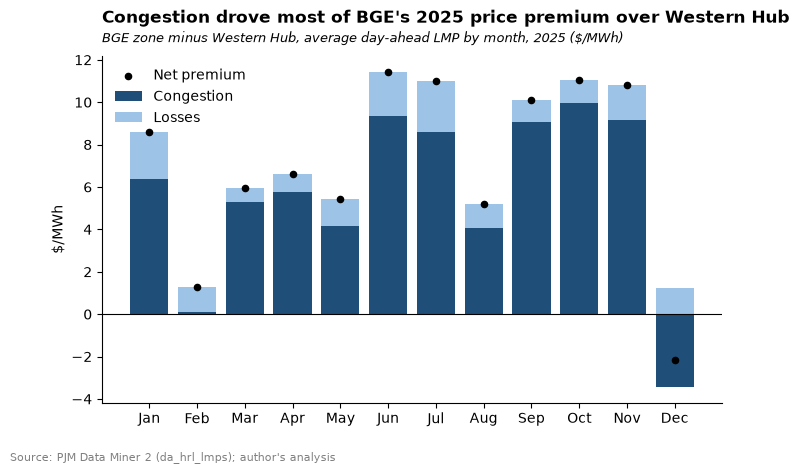

In [19]:
# Creating a chart to visualize the price differences for Exhibit 1
fig, ax = plt.subplots(figsize=(8, 4.5))

months = monthly_price_diff.index.strftime("%b")

# Congestion bars (can go below zero, e.g., December)
ax.bar(months, monthly_price_diff["congestion"], label="Congestion", color="#1f4e79")

# Loss bars stacked on top of positive congestion, or starting from zero when congestion is negative
ax.bar(months, monthly_price_diff["loss"],
       bottom=monthly_price_diff["congestion"].clip(lower=0),
       label="Losses", color="#9dc3e6")

# Dot showing the net premium (total LMP difference) for each month
ax.scatter(months, monthly_price_diff["lmp"], color="black", zorder=3, s=20,
           label="Net premium")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("$/MWh")

ax.set_title("Congestion drove most of BGE's 2025 price premium over Western Hub",
             loc="left", fontweight="bold", pad=24)
ax.text(0, 1.04, "BGE zone minus Western Hub, average day-ahead LMP by month, 2025 ($/MWh)",
        transform=ax.transAxes, fontsize=9, fontstyle="italic")

fig.text(0.01, -0.02, "Source: PJM Data Miner 2 (da_hrl_lmps); author's analysis",
         fontsize=8, color="gray")

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.savefig("../exhibits/01_bge_premium_monthly.png", dpi=300, bbox_inches="tight")
fig.savefig("../exhibits/01_bge_premium_monthly.svg", bbox_inches="tight")
plt.show()

Beginning to highlight how common price spikes and dips are

In [20]:
# Pulling DA LMP column
bge_da_iso = lmp[(lmp["market"] == "DA") & (lmp["node"] == "BGE")]
bge_da_lmps = bge_da_iso["lmp"]

In [21]:
# Sorting DA LMP column by highest to lowest value AND reseting the index to numerical order rather than time stamps
bge_da_sorted = bge_da_lmps.sort_values(ascending=False).reset_index(drop=True)

In [22]:
bge_da_sorted.head()

0    609.740467
1    607.497026
2    583.996324
3    565.384395
4    547.156123
Name: lmp, dtype: float64

In [23]:
# Pulling BGE RT LMP column
bge_rt_iso = lmp[(lmp["market"] == "RT") & (lmp["node"] == "BGE")]
bge_rt_lmps = bge_rt_iso["lmp"]

In [24]:
# Sorting RT LMP column by highest to lowest value AND reseting the index to numerical order rather than time stamps
bge_rt_sorted = bge_rt_lmps.sort_values(ascending=False).reset_index(drop=True)

In [25]:
bge_rt_sorted.head()

0    2021.929077
1    1512.014285
2    1443.848039
3    1379.990416
4    1113.684616
Name: lmp, dtype: float64

Analyzing data from bge_da_sorted

In [26]:
# Finding min, max, mean, and standard deviation in the BGE DA lmp series
bge_da_sorted.describe()

count    8760.000000
mean       57.373200
std        45.099342
min        11.911439
25%        33.648900
50%        44.910950
75%        65.564132
max       609.740467
Name: lmp, dtype: float64

- The minimum DA lmp was ~\$11.91
- The maximum DA lmp was ~\$609.74
- The standard deviation of DA lmps is ~\$45.09

In [27]:
# Finding the number of hours where da lmp is greater than $100
(bge_da_sorted >= 100).sum()


np.int64(832)

In [28]:
# Finding the percentage of hours where da lmp was greater than $100
(bge_da_sorted >= 100).mean() * 100

np.float64(9.497716894977168)

- The BGE DA lmp was greater than \$100 at 832 hourly timestamps in 2025
- The BGE DA lmp was greater than \$100 about 9.5% of the time in 2025

In [29]:
# Finding min, max, mean, and standard deviation in the BGE RT lmp series
bge_rt_sorted.describe()

count    8760.000000
mean       56.501890
std        68.252231
min        -8.609823
25%        29.280034
50%        39.199124
75%        59.449369
max      2021.929077
Name: lmp, dtype: float64

In [30]:
# Finding the number of hours where RT lmp was greater than $100
(bge_rt_sorted >= 100).sum()

np.int64(861)

In [31]:
# Finding the percentage of hours where RT lmp was greater than $100
(bge_rt_sorted >= 100).mean() * 100

np.float64(9.82876712328767)

- The minimum RT lmp was ~ -\$8.61
- The maximum RT lmp was ~ \$2,021.93
- The standard deviation of DA lmps is ~\$45.09
- The BGE RT LMP was greaeter than \$100 at 861 hourly timestamps in 2025
- The BGE RT LMP was greater than \$100 about 9.83% of the time in 2025

In [32]:
# Creating a table to find differences between DA and RT price distributions
diff = (bge_rt_sorted - bge_da_sorted)

In [33]:
diff.describe()

count    8760.000000
mean       -0.871311
std        28.856176
min       -20.521262
25%        -5.721152
50%        -4.762700
75%        -3.496627
max      1412.188610
Name: lmp, dtype: float64

In [34]:
# Finding the number of times where RT lmp price distribution was at least $28 greater than the DA lmp price distribution
diff = (bge_rt_sorted - bge_da_sorted)
(diff >= 28).sum()

np.int64(270)

In [35]:
# Finding the percentage of hours where RT lmp distribution was at least $50 greater than DA lmp distribution 
diff = (bge_rt_sorted - bge_da_sorted)
(diff >= 28).mean() * 100

np.float64(3.0821917808219177)

In [36]:
# Finding the percentage where RT lmp distribution was at least $50 greater than DA lmp distribution
diff = (bge_rt_sorted - bge_da_sorted)
(diff >= 50).mean() * 100

np.float64(1.5068493150684932)

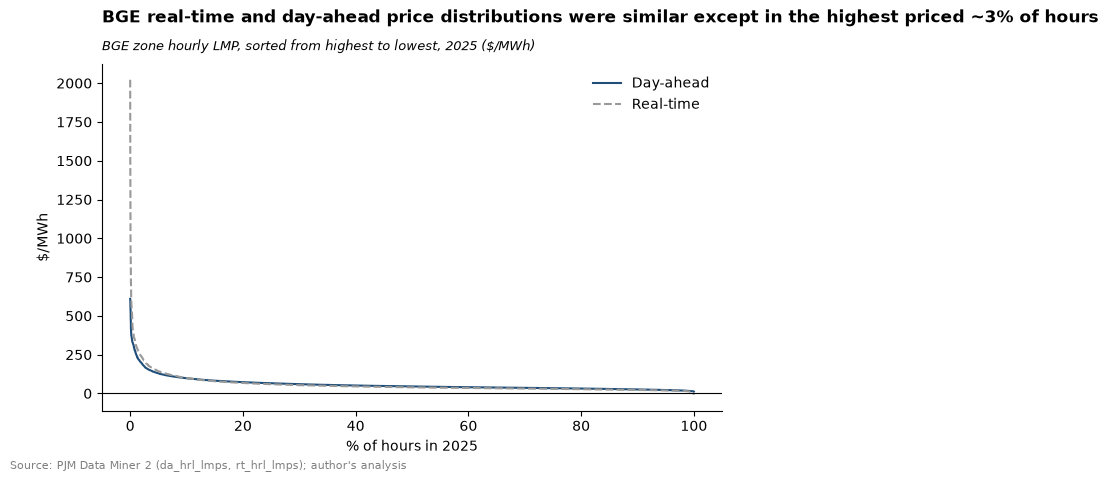

In [37]:
# Creating a chart to visualize results for Exhibit 2
fig, ax = plt.subplots(figsize=(8, 4.5))

pct_hours = [i / len(bge_da_sorted) * 100 for i in range(len(bge_da_sorted))]   # x-axis: 0-100% of hours

ax.plot(pct_hours, bge_da_sorted, label="Day-ahead", color="#1f4e79", linewidth=1.5)
ax.plot(pct_hours, bge_rt_sorted, label="Real-time", color="#999999", linewidth=1.5, linestyle="--")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("% of hours in 2025")
ax.set_ylabel("$/MWh")

ax.set_title("BGE real-time and day-ahead price distributions were similar except in the highest priced ~3% of hours",
             loc="left", fontweight="bold", pad=30)
ax.text(0, 1.04, "BGE zone hourly LMP, sorted from highest to lowest, 2025 ($/MWh)",
        transform=ax.transAxes, fontsize=9, fontstyle="italic")

fig.text(0.01, -0.02, "Source: PJM Data Miner 2 (da_hrl_lmps, rt_hrl_lmps); author's analysis",
         fontsize=8, color="gray")

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.savefig("../exhibits/02_bge_price_duration.png", dpi=300, bbox_inches="tight")
fig.savefig("../exhibits/02_bge_price_duration.svg", bbox_inches="tight")
plt.show()

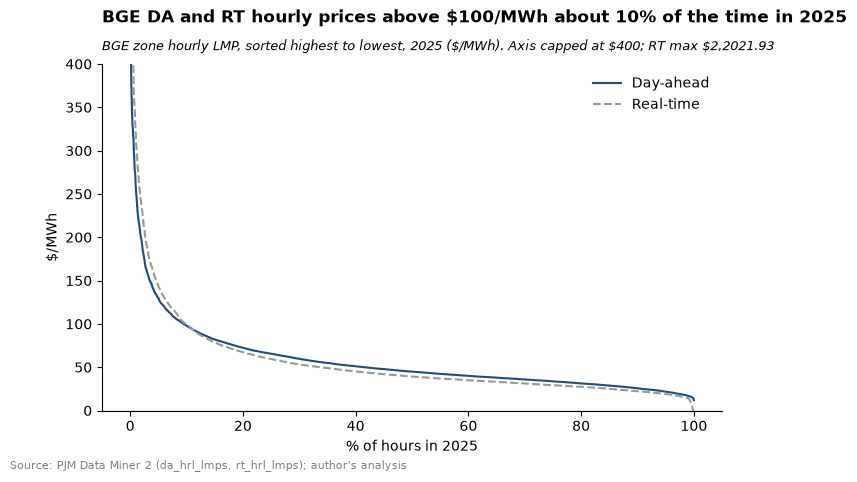

In [38]:
# Creating a chart to visualize results for Exhibit 3
fig, ax = plt.subplots(figsize=(8, 4.5))

pct_hours = [i / len(bge_da_sorted) * 100 for i in range(len(bge_da_sorted))]   # x-axis: 0-100% of hours

ax.plot(pct_hours, bge_da_sorted, label="Day-ahead", color="#1f4e79", linewidth=1.5)
ax.plot(pct_hours, bge_rt_sorted, label="Real-time", color="#999999", linewidth=1.5, linestyle="--")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("% of hours in 2025")
ax.set_ylabel("$/MWh")

ax.set_title("BGE DA and RT hourly prices above $100/MWh about 10% of the time in 2025",
             loc="left", fontweight="bold", pad=30)
ax.text(0, 1.04, "BGE zone hourly LMP, sorted highest to lowest, 2025 ($/MWh). Axis capped at $400; RT max $2,2021.93",
        transform=ax.transAxes, fontsize=9, fontstyle="italic")

fig.text(0.01, -0.02, "Source: PJM Data Miner 2 (da_hrl_lmps, rt_hrl_lmps); author's analysis",
         fontsize=8, color="gray")

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

ax.set_ylim(0, 400)
fig.savefig("../exhibits/03_bge_price_duration.png", dpi=300, bbox_inches="tight")
fig.savefig("../exhibits/03_bge_price_duration.svg", bbox_inches="tight")
plt.show()

Now making an hourly comparison between DA and RT price differences 

In [39]:
# Hour-by-hour RT minus DA at BGE, matched on UTC timestamp
hourly_diff = bge_rt_lmps - bge_da_lmps

assert len(hourly_diff) == 8760, f"Expected 8,760 hours, got {len(hourly_diff)}"
assert hourly_diff.isna().sum() == 0, "Some hours didn't match between RT and DA"

hourly_diff.describe()

count    8760.000000
mean       -0.871311
std        52.597697
min      -353.395701
25%       -12.834397
50%        -4.099540
75%         2.149751
max      1482.900109
Name: lmp, dtype: float64

In [40]:
(hourly_diff.abs() >= 50).mean() * 100    # % of hours where RT and DA differed by $50+, either direction
(hourly_diff >= 50).mean() * 100          # % of hours where RT was $50+ ABOVE DA
hourly_diff.mean()                         # average RT minus DA

print(f"Hours where RT and DA differed by $50+ (either direction): {(hourly_diff.abs() >= 50).mean() * 100:.1f}%")
print(f"Hours where RT was $50+ above DA: {(hourly_diff >= 50).mean() * 100:.1f}%")
print(f"Average RT minus DA: ${hourly_diff.mean():.2f}/MWh")

Hours where RT and DA differed by $50+ (either direction): 8.6%
Hours where RT was $50+ above DA: 4.9%
Average RT minus DA: $-0.87/MWh


- Hours where RT and DA differed by \$50+ (either direction): 8.6%
- Hours where RT was \$50+ above DA: 4.9%
- Average RT minus DA: \$-0.87/MWh

In [41]:
# The 10 hours with the largest RT spikes over DA, shown in Eastern time
hourly_diff.nlargest(10).tz_convert("America/New_York")

2025-06-24 18:00:00-04:00    1482.900109
2025-06-23 20:00:00-04:00    1163.914799
2025-06-23 19:00:00-04:00    1091.694222
2025-06-24 19:00:00-04:00    1006.887683
2025-05-02 17:00:00-04:00     951.892346
2025-06-22 19:00:00-04:00     824.337995
2025-04-08 07:00:00-04:00     744.055790
2025-10-03 17:00:00-04:00     718.819891
2025-11-18 07:00:00-05:00     666.390800
2025-11-17 07:00:00-05:00     570.656362
Name: lmp, dtype: float64

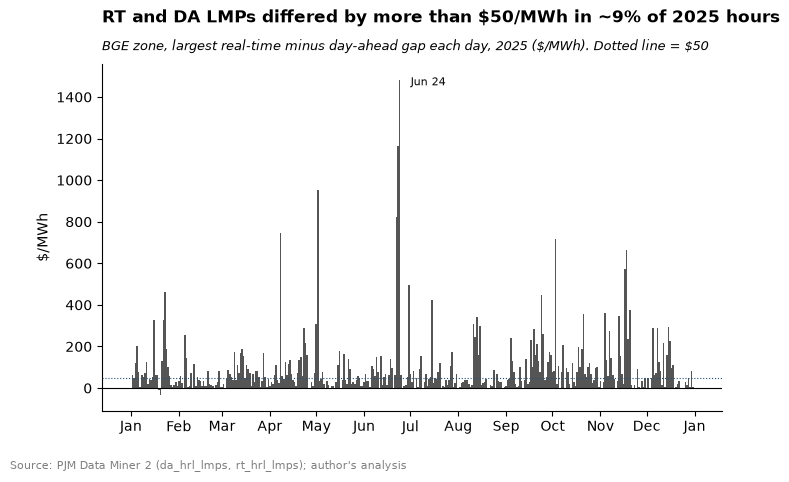

In [42]:
# Generating table to visualize findings 
import matplotlib.dates as mdates

# Convert to Eastern time so the x-axis follows the local calendar
hourly_diff_ept = hourly_diff.tz_convert("America/New_York")

# Largest RT-minus-DA gap each day (365 bars instead of 8,760 hourly points)
daily_max = hourly_diff_ept.resample("D").max()

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(daily_max.index, daily_max.values, width=1, color="#555555")

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(50, color="#1f4e79", linewidth=0.8, linestyle=":")   # $50 reference line

# Label the largest spike with its date
peak = daily_max.idxmax()
ax.annotate(f"{peak:%b %d}", xy=(peak, daily_max.max()),
            xytext=(8, -4), textcoords="offset points", fontsize=8)

# Month labels on the x-axis (locator and formatter both in Eastern time)
ax.xaxis.set_major_locator(mdates.MonthLocator(tz=hourly_diff_ept.index.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b", tz=hourly_diff_ept.index.tz))

ax.set_ylabel("$/MWh")

ax.set_title("RT and DA LMPs differed by more than \\$50/MWh in ~9% of 2025 hours",
             loc="left", fontweight="bold", pad=30)
ax.text(0, 1.04, "BGE zone, largest real-time minus day-ahead gap each day, 2025 (\\$/MWh). Dotted line = \\$50",
        transform=ax.transAxes, fontsize=9, fontstyle="italic")

fig.text(0.01, -0.02, "Source: PJM Data Miner 2 (da_hrl_lmps, rt_hrl_lmps); author's analysis",
         fontsize=8, color="gray")

ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../exhibits/04_bge_rt_minus_da_hourly.png", dpi=300, bbox_inches="tight")
fig.savefig("../exhibits/04_bge_rt_minus_da_hourly.svg", bbox_inches="tight")
plt.show()